In [1]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


file_path = '/home/znb/dataset/FTP Enumeration/Dataset.csv'

# Load the dataset
df = pd.read_csv(file_path)
df


/tmp/ipykernel_3398900/469589498.py:13: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


,src_ip,dst_ip,src_port,dst_port,protocol,timestamp,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,...,bwd_blk_rate_avg,fwd_seg_size_avg,bwd_seg_size_avg,cwr_flag_count,subflow_fwd_pkts,subflow_bwd_pkts,subflow_fwd_byts,subflow_bwd_byts,Label,Label1
0,192.168.0.38,192.168.10.224,34026,80,6,2026-06-12,15:36:09,0.000472,7.500000e+05,10593.220339,...,0.0,0.0,70.000000,74.000000,0,4,1,280,Malicious,Vulnerability-Scan
1,192.168.0.38,192.168.10.224,48348,443,6,2026-06-12,15:36:09,0.000496,5.685484e+05,8064.516129,...,0.0,0.0,69.333333,74.000000,0,3,1,208,Malicious,Vulnerability-Scan
2,192.168.0.38,192.168.10.224,44684,111,6,2026-06-12,15:36:09,0.000011,1.836364e+07,272727.272727,...,0.0,0.0,74.000000,54.000000,0,2,1,148,Malicious,Vulnerability-Scan
3,192.168.0.38,192.168.10.224,55330,993,6,2026-06-12,15:36:09,0.000003,6.733333e+07,1000000.000000,...,0.0,0.0,74.000000,54.000000,0,2,1,148,Malicious,Vulnerability-Scan
4,192.168.0.38,192.168.10.224,37904,113,6,2026-06-12,15:36:09,0.000004,5.050000e+07,750000.000000,...,0.0,0.0,74.000000,54.000000,0,2,1,148,Malicious,Vulnerability-Scan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376000,192.168.0.38,192.168.10.224,50550,21,6,2026-06-18,15:00:09,37.409257,1.466749e+02,1.951389,...,0.0,0.0,70.783784,79.666667,0,37,36,2619,Malicious,FTP-BruteForce
376001,192.168.0.38,192.168.10.224,50566,21,6,2026-06-18,15:00:09,52.994919,1.544865e+02,2.056801,...,0.0,0.0,70.636364,79.666667,0,55,54,3885,Malicious,FTP-BruteForce
376002,192.168.0.38,192.168.10.224,50492,21,6,2026-06-18,15:00:09,52.992986,1.345461e+02,1.830431,...,0.0,0.0,68.961538,78.755556,0,52,45,3586,Malicious,FTP-BruteForce
376003,192.168.0.38,192.168.10.224,50572,21,6,2026-06-18,15:00:09,52.995054,1.375411e+02,1.830359,...,0.0,0.0,70.714286,79.666667,0,49,48,3465,Malicious,FTP-BruteForce


In [2]:
file_path1 = '/home/znb/dataset/Dataset.csv'

# Load the dataset
df2 = pd.read_csv(file_path1)
df2


,src_ip,dst_ip,src_port,dst_port,protocol,timestamp,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,...,fwd_blk_rate_avg,bwd_blk_rate_avg,fwd_seg_size_avg,bwd_seg_size_avg,cwr_flag_count,subflow_fwd_pkts,subflow_bwd_pkts,subflow_fwd_byts,subflow_bwd_byts,Label
0,192.168.0.22,8.8.8.8,49547,53,17,1/20/2026,10:53,40264.000000,1.000000,1.000000,...,1.0,8.000000e+00,0.000000,0.000000,0.000000,0,0.0,0.0,0,DNS
1,192.168.0.22,8.8.8.8,33536,53,17,1/20/2026,10:53,48602.000000,1.000000,1.000000,...,1.0,8.000000e+00,0.000000,0.000000,0.000000,0,0.0,0.0,0,DNS
2,192.168.0.22,8.8.8.8,39600,53,17,1/20/2026,10:53,38258.000000,1.000000,1.000000,...,1.0,8.000000e+00,0.000000,0.000000,0.000000,0,0.0,0.0,0,DNS
3,192.168.0.22,8.8.8.8,58225,53,17,1/20/2026,10:53,38665.000000,1.000000,1.000000,...,1.0,8.000000e+00,0.000000,0.000000,0.000000,0,0.0,0.0,0,DNS
4,192.168.0.22,8.8.8.8,58643,53,17,1/20/2026,10:53,50153.000000,1.000000,1.000000,...,1.0,8.000000e+00,0.000000,0.000000,0.000000,0,0.0,0.0,0,DNS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
278407,192.168.10.224,2.19.193.216,39830,443,6,2026-07-14,15:42:27,1.257608,8864.447427,31.011253,...,5.0,1.587645e+07,11313.622779,376.400000,190.526316,0,20.0,19.0,7528,Benign
278408,192.168.10.224,2.19.193.216,39844,443,6,2026-07-14,15:42:27,0.660396,4968.231183,21.199402,...,0.0,0.000000e+00,0.000000,295.000000,125.200000,0,9.0,5.0,2655,Benign
278409,192.168.10.224,2.19.193.216,39854,443,6,2026-07-14,15:42:28,0.902561,7695.878727,19.943250,...,0.0,0.000000e+00,0.000000,251.800000,553.500000,0,10.0,8.0,2518,Benign
278410,192.168.10.71,224.0.0.252,61672,5355,17,2026-07-14,15:42:29,0.411714,546.495868,7.286612,...,0.0,0.000000e+00,0.000000,75.000000,0.000000,0,3.0,0.0,225,Benign


In [3]:
df2['Label'] = 'Benign'
df2

,src_ip,dst_ip,src_port,dst_port,protocol,timestamp,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,...,fwd_blk_rate_avg,bwd_blk_rate_avg,fwd_seg_size_avg,bwd_seg_size_avg,cwr_flag_count,subflow_fwd_pkts,subflow_bwd_pkts,subflow_fwd_byts,subflow_bwd_byts,Label
0,192.168.0.22,8.8.8.8,49547,53,17,1/20/2026,10:53,40264.000000,1.000000,1.000000,...,1.0,8.000000e+00,0.000000,0.000000,0.000000,0,0.0,0.0,0,Benign
1,192.168.0.22,8.8.8.8,33536,53,17,1/20/2026,10:53,48602.000000,1.000000,1.000000,...,1.0,8.000000e+00,0.000000,0.000000,0.000000,0,0.0,0.0,0,Benign
2,192.168.0.22,8.8.8.8,39600,53,17,1/20/2026,10:53,38258.000000,1.000000,1.000000,...,1.0,8.000000e+00,0.000000,0.000000,0.000000,0,0.0,0.0,0,Benign
3,192.168.0.22,8.8.8.8,58225,53,17,1/20/2026,10:53,38665.000000,1.000000,1.000000,...,1.0,8.000000e+00,0.000000,0.000000,0.000000,0,0.0,0.0,0,Benign
4,192.168.0.22,8.8.8.8,58643,53,17,1/20/2026,10:53,50153.000000,1.000000,1.000000,...,1.0,8.000000e+00,0.000000,0.000000,0.000000,0,0.0,0.0,0,Benign
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
278407,192.168.10.224,2.19.193.216,39830,443,6,2026-07-14,15:42:27,1.257608,8864.447427,31.011253,...,5.0,1.587645e+07,11313.622779,376.400000,190.526316,0,20.0,19.0,7528,Benign
278408,192.168.10.224,2.19.193.216,39844,443,6,2026-07-14,15:42:27,0.660396,4968.231183,21.199402,...,0.0,0.000000e+00,0.000000,295.000000,125.200000,0,9.0,5.0,2655,Benign
278409,192.168.10.224,2.19.193.216,39854,443,6,2026-07-14,15:42:28,0.902561,7695.878727,19.943250,...,0.0,0.000000e+00,0.000000,251.800000,553.500000,0,10.0,8.0,2518,Benign
278410,192.168.10.71,224.0.0.252,61672,5355,17,2026-07-14,15:42:29,0.411714,546.495868,7.286612,...,0.0,0.000000e+00,0.000000,75.000000,0.000000,0,3.0,0.0,225,Benign


In [4]:

mer_df = pd.concat([df,df2], ignore_index=True)

In [5]:
mer_df

,src_ip,dst_ip,src_port,dst_port,protocol,timestamp,flow_duration,flow_byts_s,flow_pkts_s,fwd_pkts_s,...,bwd_blk_rate_avg,fwd_seg_size_avg,bwd_seg_size_avg,cwr_flag_count,subflow_fwd_pkts,subflow_bwd_pkts,subflow_fwd_byts,subflow_bwd_byts,Label,Label1
0,192.168.0.38,192.168.10.224,34026,80,6,2026-06-12,15:36:09,0.000472,7.500000e+05,10593.220339,...,0.000000e+00,0.000000,70.000000,74.000000,0,4.0,1.0,280,Malicious,Vulnerability-Scan
1,192.168.0.38,192.168.10.224,48348,443,6,2026-06-12,15:36:09,0.000496,5.685484e+05,8064.516129,...,0.000000e+00,0.000000,69.333333,74.000000,0,3.0,1.0,208,Malicious,Vulnerability-Scan
2,192.168.0.38,192.168.10.224,44684,111,6,2026-06-12,15:36:09,0.000011,1.836364e+07,272727.272727,...,0.000000e+00,0.000000,74.000000,54.000000,0,2.0,1.0,148,Malicious,Vulnerability-Scan
3,192.168.0.38,192.168.10.224,55330,993,6,2026-06-12,15:36:09,0.000003,6.733333e+07,1000000.000000,...,0.000000e+00,0.000000,74.000000,54.000000,0,2.0,1.0,148,Malicious,Vulnerability-Scan
4,192.168.0.38,192.168.10.224,37904,113,6,2026-06-12,15:36:09,0.000004,5.050000e+07,750000.000000,...,0.000000e+00,0.000000,74.000000,54.000000,0,2.0,1.0,148,Malicious,Vulnerability-Scan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
654412,192.168.10.224,2.19.193.216,39830,443,6,2026-07-14,15:42:27,1.257608,8.864447e+03,31.011253,...,1.587645e+07,11313.622779,376.400000,190.526316,0,20.0,19.0,7528,Benign,NaN
654413,192.168.10.224,2.19.193.216,39844,443,6,2026-07-14,15:42:27,0.660396,4.968231e+03,21.199402,...,0.000000e+00,0.000000,295.000000,125.200000,0,9.0,5.0,2655,Benign,NaN
654414,192.168.10.224,2.19.193.216,39854,443,6,2026-07-14,15:42:28,0.902561,7.695879e+03,19.943250,...,0.000000e+00,0.000000,251.800000,553.500000,0,10.0,8.0,2518,Benign,NaN
654415,192.168.10.71,224.0.0.252,61672,5355,17,2026-07-14,15:42:29,0.411714,5.464959e+02,7.286612,...,0.000000e+00,0.000000,75.000000,0.000000,0,3.0,0.0,225,Benign,NaN


In [6]:
mer_df["Label"].value_counts()
mer_df = mer_df.drop(['Label1'], axis=1)   # X is all columns except the label

In [7]:
mer_df = mer_df.drop(['src_ip','dst_ip','src_port','dst_port','protocol','timestamp'], axis=1)   # X is all columns except the label

In [8]:
merged_df=mer_df

In [9]:
print(merged_df.shape)

(654417, 77)


In [10]:
merged_df = merged_df.sample(frac=1, random_state=42).reset_index(drop=True)
print(merged_df.head())

  flow_duration  flow_byts_s   flow_pkts_s      fwd_pkts_s     bwd_pkts_s  \
0         16:08     0.012852  1.900000e+01       24.000000    1372.000000   
1      15:40:36     0.003488  1.829128e+05     2580.275229    1720.183486   
2      15:03:02     0.000004  4.350000e+07   750000.000000  500000.000000   
3      15:03:03     0.000003  5.800000e+07  1000000.000000  666666.666667   
4      12:14:11     0.000000  0.000000e+00        0.000000       0.000000   

    tot_fwd_pkts  tot_bwd_pkts  totlen_fwd_pkts  totlen_bwd_pkts  \
0    2004.000000            82               66        72.210526   
1     860.091743             6                3       412.000000   
2  250000.000000             2                1       120.000000   
3  333333.333333             2                1       120.000000   
4       0.000000             2                0       150.000000   

   fwd_pkt_len_max  ...  fwd_blk_rate_avg  bwd_blk_rate_avg  fwd_seg_size_avg  \
0         5.726935  ...              10.0      

In [11]:
# Show unique values in the 'Label' column
print(merged_df["Label"].unique())

['Benign' 'Malicious']


In [12]:
from sklearn.preprocessing import LabelEncoder
le_label = LabelEncoder()

# Encode columns
merged_df["Label"] = le_label.fit_transform(merged_df["Label"])


In [13]:
# Get unique label classes
label_classes = merged_df['Label'].unique()
print("Label Classes:", label_classes)

Label Classes: [0 1]


In [14]:
from sklearn.preprocessing import StandardScaler

# Columns to exclude from scaling
non_numeric_cols = ['Label']

# Select only numeric columns from merged_df
numeric_cols = merged_df.select_dtypes(include=['int64', 'float64']).columns
cols_to_scale = [col for col in numeric_cols if col not in non_numeric_cols]

# Replace infinite values with NaN
merged_df[cols_to_scale] = merged_df[cols_to_scale].replace([np.inf, -np.inf], np.nan)

# We will fit the scaler later on the selected features.
# For now, just show the head without scaling.
print(merged_df.head())

  flow_duration  flow_byts_s   flow_pkts_s      fwd_pkts_s     bwd_pkts_s  \
0         16:08     0.012852  1.900000e+01       24.000000    1372.000000   
1      15:40:36     0.003488  1.829128e+05     2580.275229    1720.183486   
2      15:03:02     0.000004  4.350000e+07   750000.000000  500000.000000   
3      15:03:03     0.000003  5.800000e+07  1000000.000000  666666.666667   
4      12:14:11     0.000000  0.000000e+00        0.000000       0.000000   

    tot_fwd_pkts  tot_bwd_pkts  totlen_fwd_pkts  totlen_bwd_pkts  \
0    2004.000000            82               66        72.210526   
1     860.091743             6                3       412.000000   
2  250000.000000             2                1       120.000000   
3  333333.333333             2                1       120.000000   
4       0.000000             2                0       150.000000   

   fwd_pkt_len_max  ...  fwd_blk_rate_avg  bwd_blk_rate_avg  fwd_seg_size_avg  \
0         5.726935  ...              10.0      

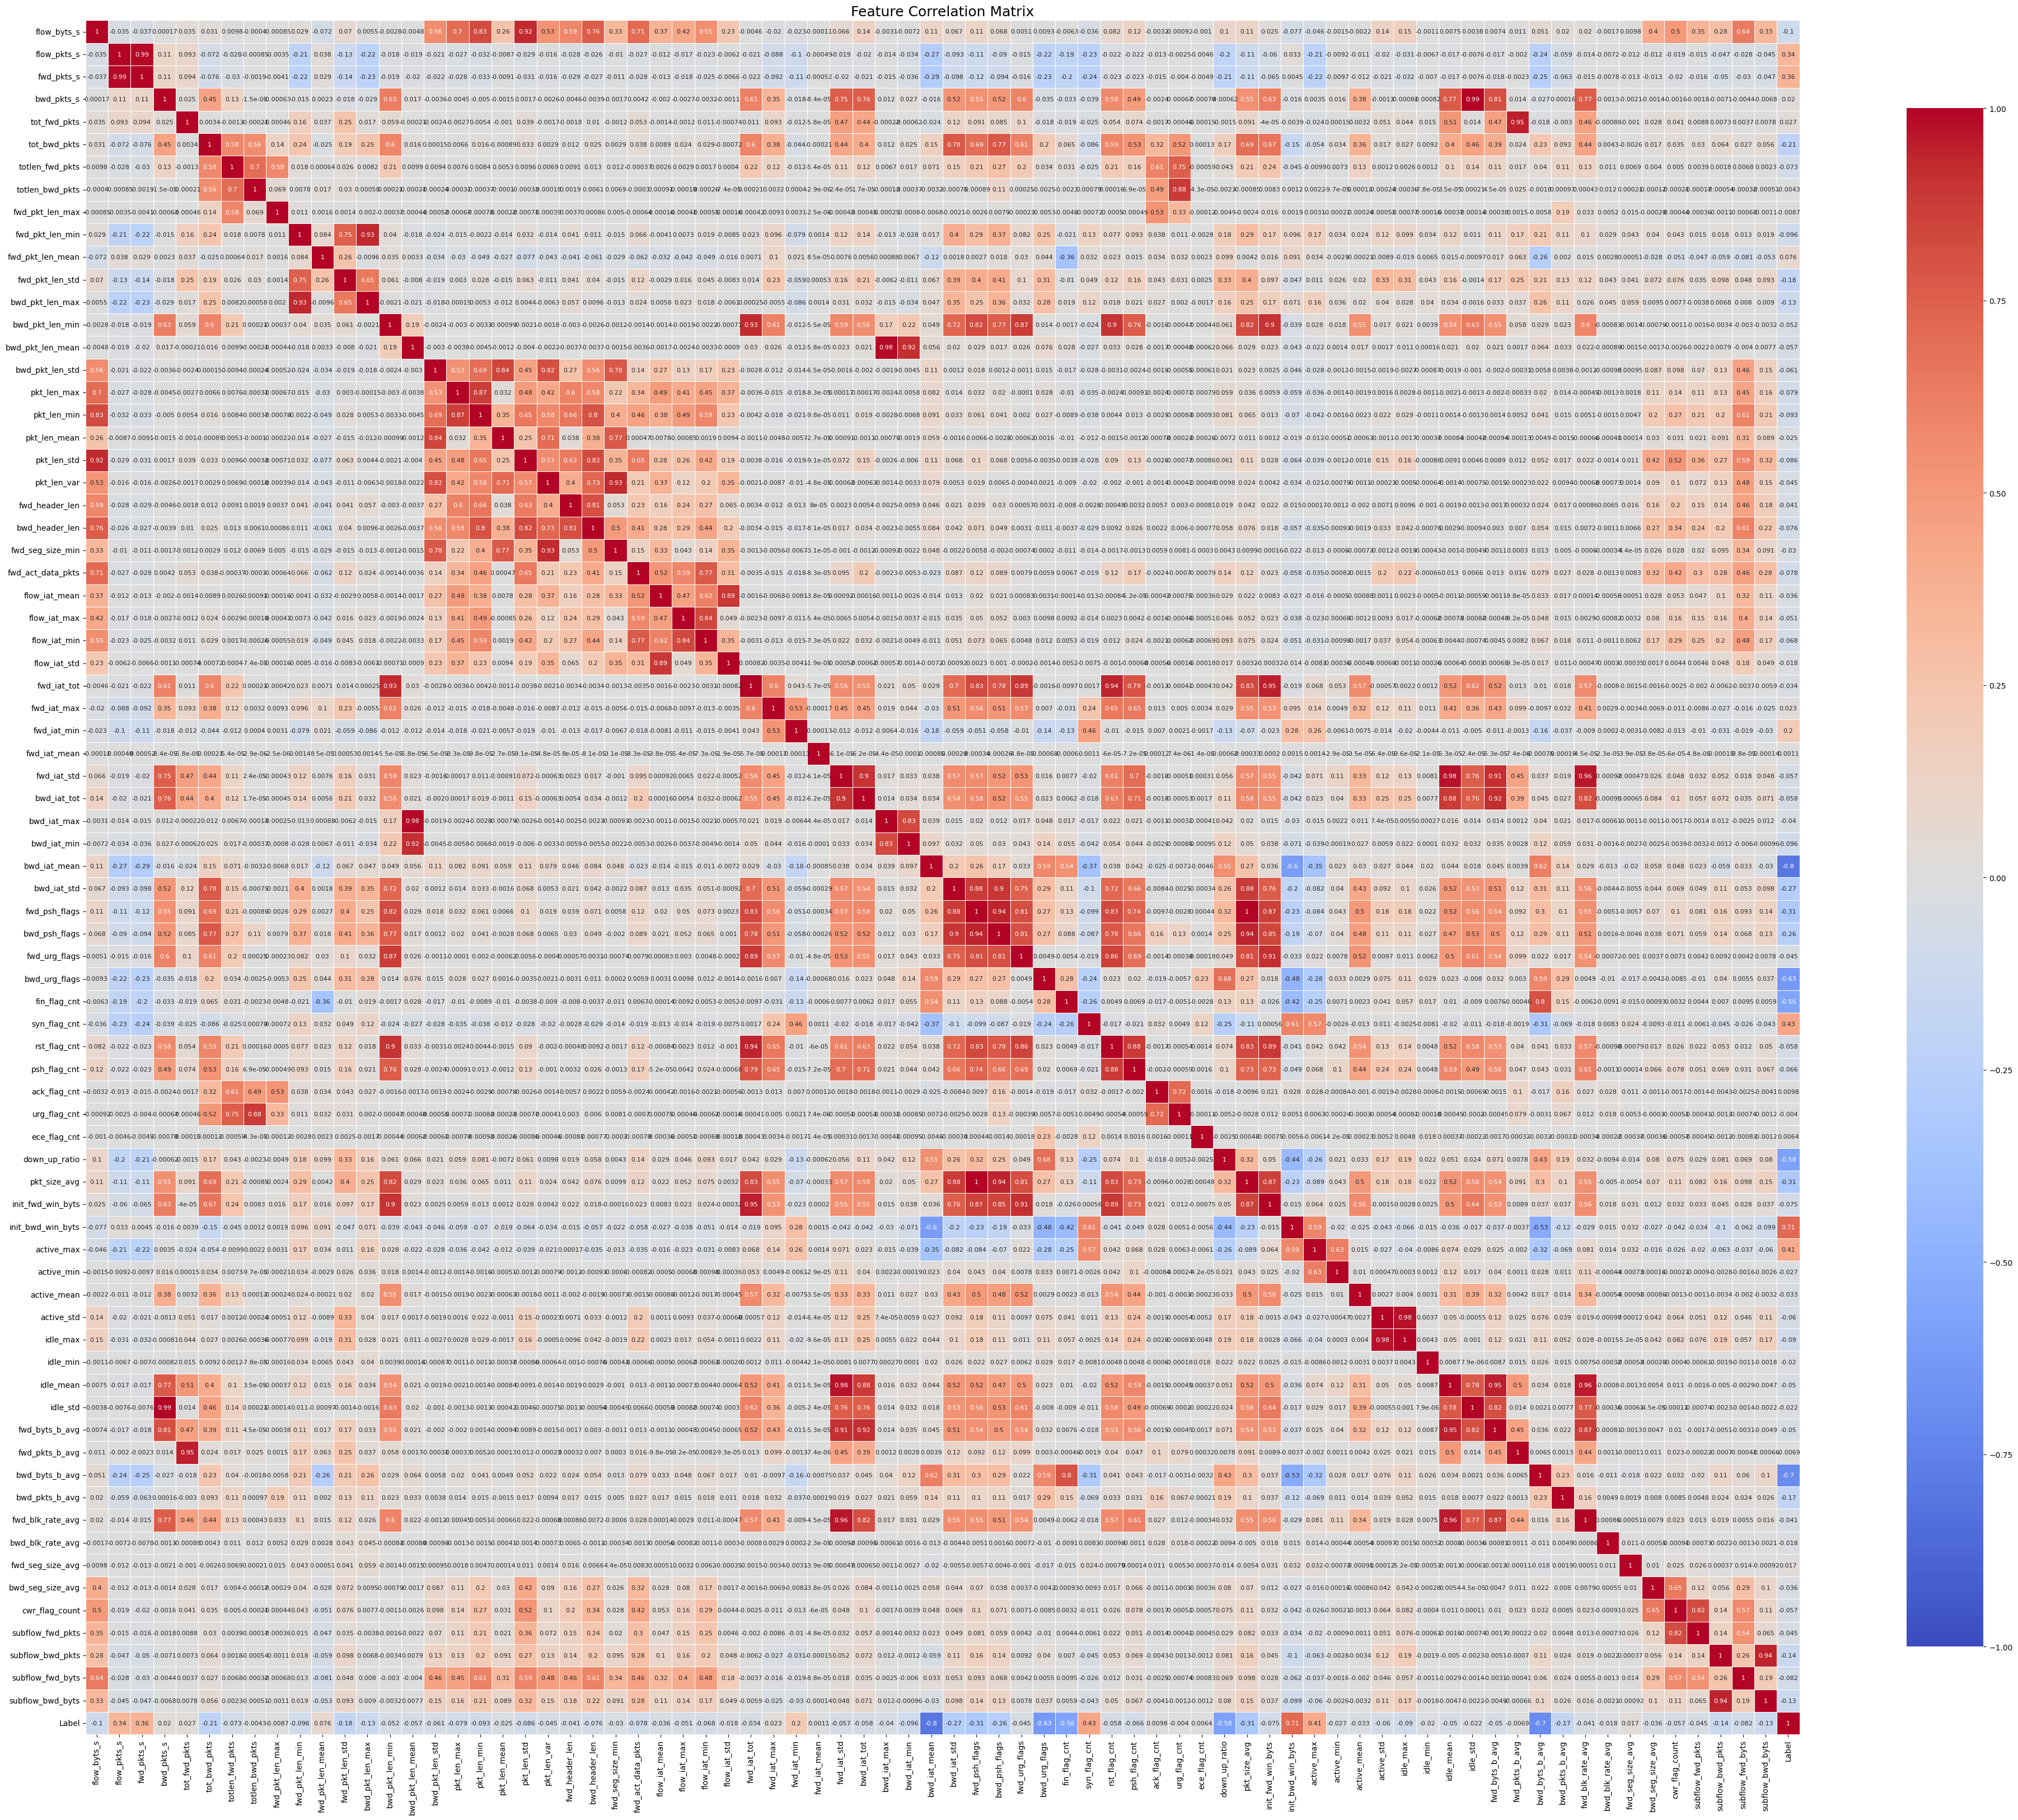

Top 20 highest correlations:
fwd_psh_flags     pkt_size_avg        0.999229
pkt_size_avg      fwd_psh_flags       0.999229
bwd_pkts_s        idle_std            0.993056
idle_std          bwd_pkts_s          0.993056
fwd_pkts_s        flow_pkts_s         0.985518
flow_pkts_s       fwd_pkts_s          0.985518
bwd_iat_max       bwd_pkt_len_mean    0.984621
bwd_pkt_len_mean  bwd_iat_max         0.984621
active_std        idle_max            0.975942
idle_max          active_std          0.975942
fwd_iat_std       idle_mean           0.975817
idle_mean         fwd_iat_std         0.975817
fwd_iat_std       fwd_blk_rate_avg    0.963931
fwd_blk_rate_avg  fwd_iat_std         0.963931
idle_mean         fwd_blk_rate_avg    0.958974
fwd_blk_rate_avg  idle_mean           0.958974
tot_fwd_pkts      fwd_pkts_b_avg      0.952001
fwd_pkts_b_avg    tot_fwd_pkts        0.952001
idle_mean         fwd_byts_b_avg      0.948738
fwd_byts_b_avg    idle_mean           0.948738
dtype: float64


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select ONLY numeric columns automatically
numeric_df = merged_df.select_dtypes(include=[np.number])

# Calculate correlation matrix
corr_matrix = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(40, 35))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot=True,
    annot_kws={'size': 8}
)

plt.title('Feature Correlation Matrix', fontsize=18)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# =========================================================
# HIGH CORRELATIONS
# =========================================================

high_corr = corr_matrix.abs().unstack()

# Remove duplicate/self correlations
high_corr = high_corr[
    high_corr < 1
].sort_values(ascending=False)

print("Top 20 highest correlations:")
print(high_corr.head(20))

In [16]:


import numpy as np
import pandas as pd

# Select only numeric feature columns (exclude target column)
numeric_features = (
    merged_df
    .drop(columns=["Label"], errors="ignore")
    .select_dtypes(include=np.number)
)

# Compute absolute correlation matrix
corr_matrix = numeric_features.corr().abs()

# Extract upper triangle
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find highly correlated features
to_drop = [
    column for column in upper.columns
    if any(upper[column] > 0.80)
]

print("Number of features to drop:", len(to_drop))
print("\nFeatures to drop:")
print(to_drop)

# Drop correlated features from original dataframe
merged_df_reduced = merged_df.drop(columns=to_drop)

print("\nOriginal shape:", merged_df.shape)
print("Reduced shape:", merged_df_reduced.shape)

# Verify Label still exists
print("\nIs 'Label' present in reduced dataset?",
      "Label" in merged_df_reduced.columns)

Number of features to drop: 31

Features to drop:
['fwd_pkts_s', 'bwd_pkt_len_max', 'pkt_len_min', 'pkt_len_mean', 'pkt_len_std', 'pkt_len_var', 'bwd_header_len', 'fwd_seg_size_min', 'flow_iat_min', 'flow_iat_std', 'fwd_iat_tot', 'bwd_iat_tot', 'bwd_iat_max', 'bwd_iat_min', 'fwd_psh_flags', 'bwd_psh_flags', 'fwd_urg_flags', 'rst_flag_cnt', 'psh_flag_cnt', 'urg_flag_cnt', 'pkt_size_avg', 'init_fwd_win_byts', 'idle_max', 'idle_mean', 'idle_std', 'fwd_byts_b_avg', 'fwd_pkts_b_avg', 'bwd_byts_b_avg', 'fwd_blk_rate_avg', 'subflow_fwd_pkts', 'subflow_bwd_byts']

Original shape: (654417, 77)
Reduced shape: (654417, 46)

Is 'Label' present in reduced dataset? True


In [17]:
merged_df=merged_df_reduced

Saved: Feature_Correlation_Matrix.png


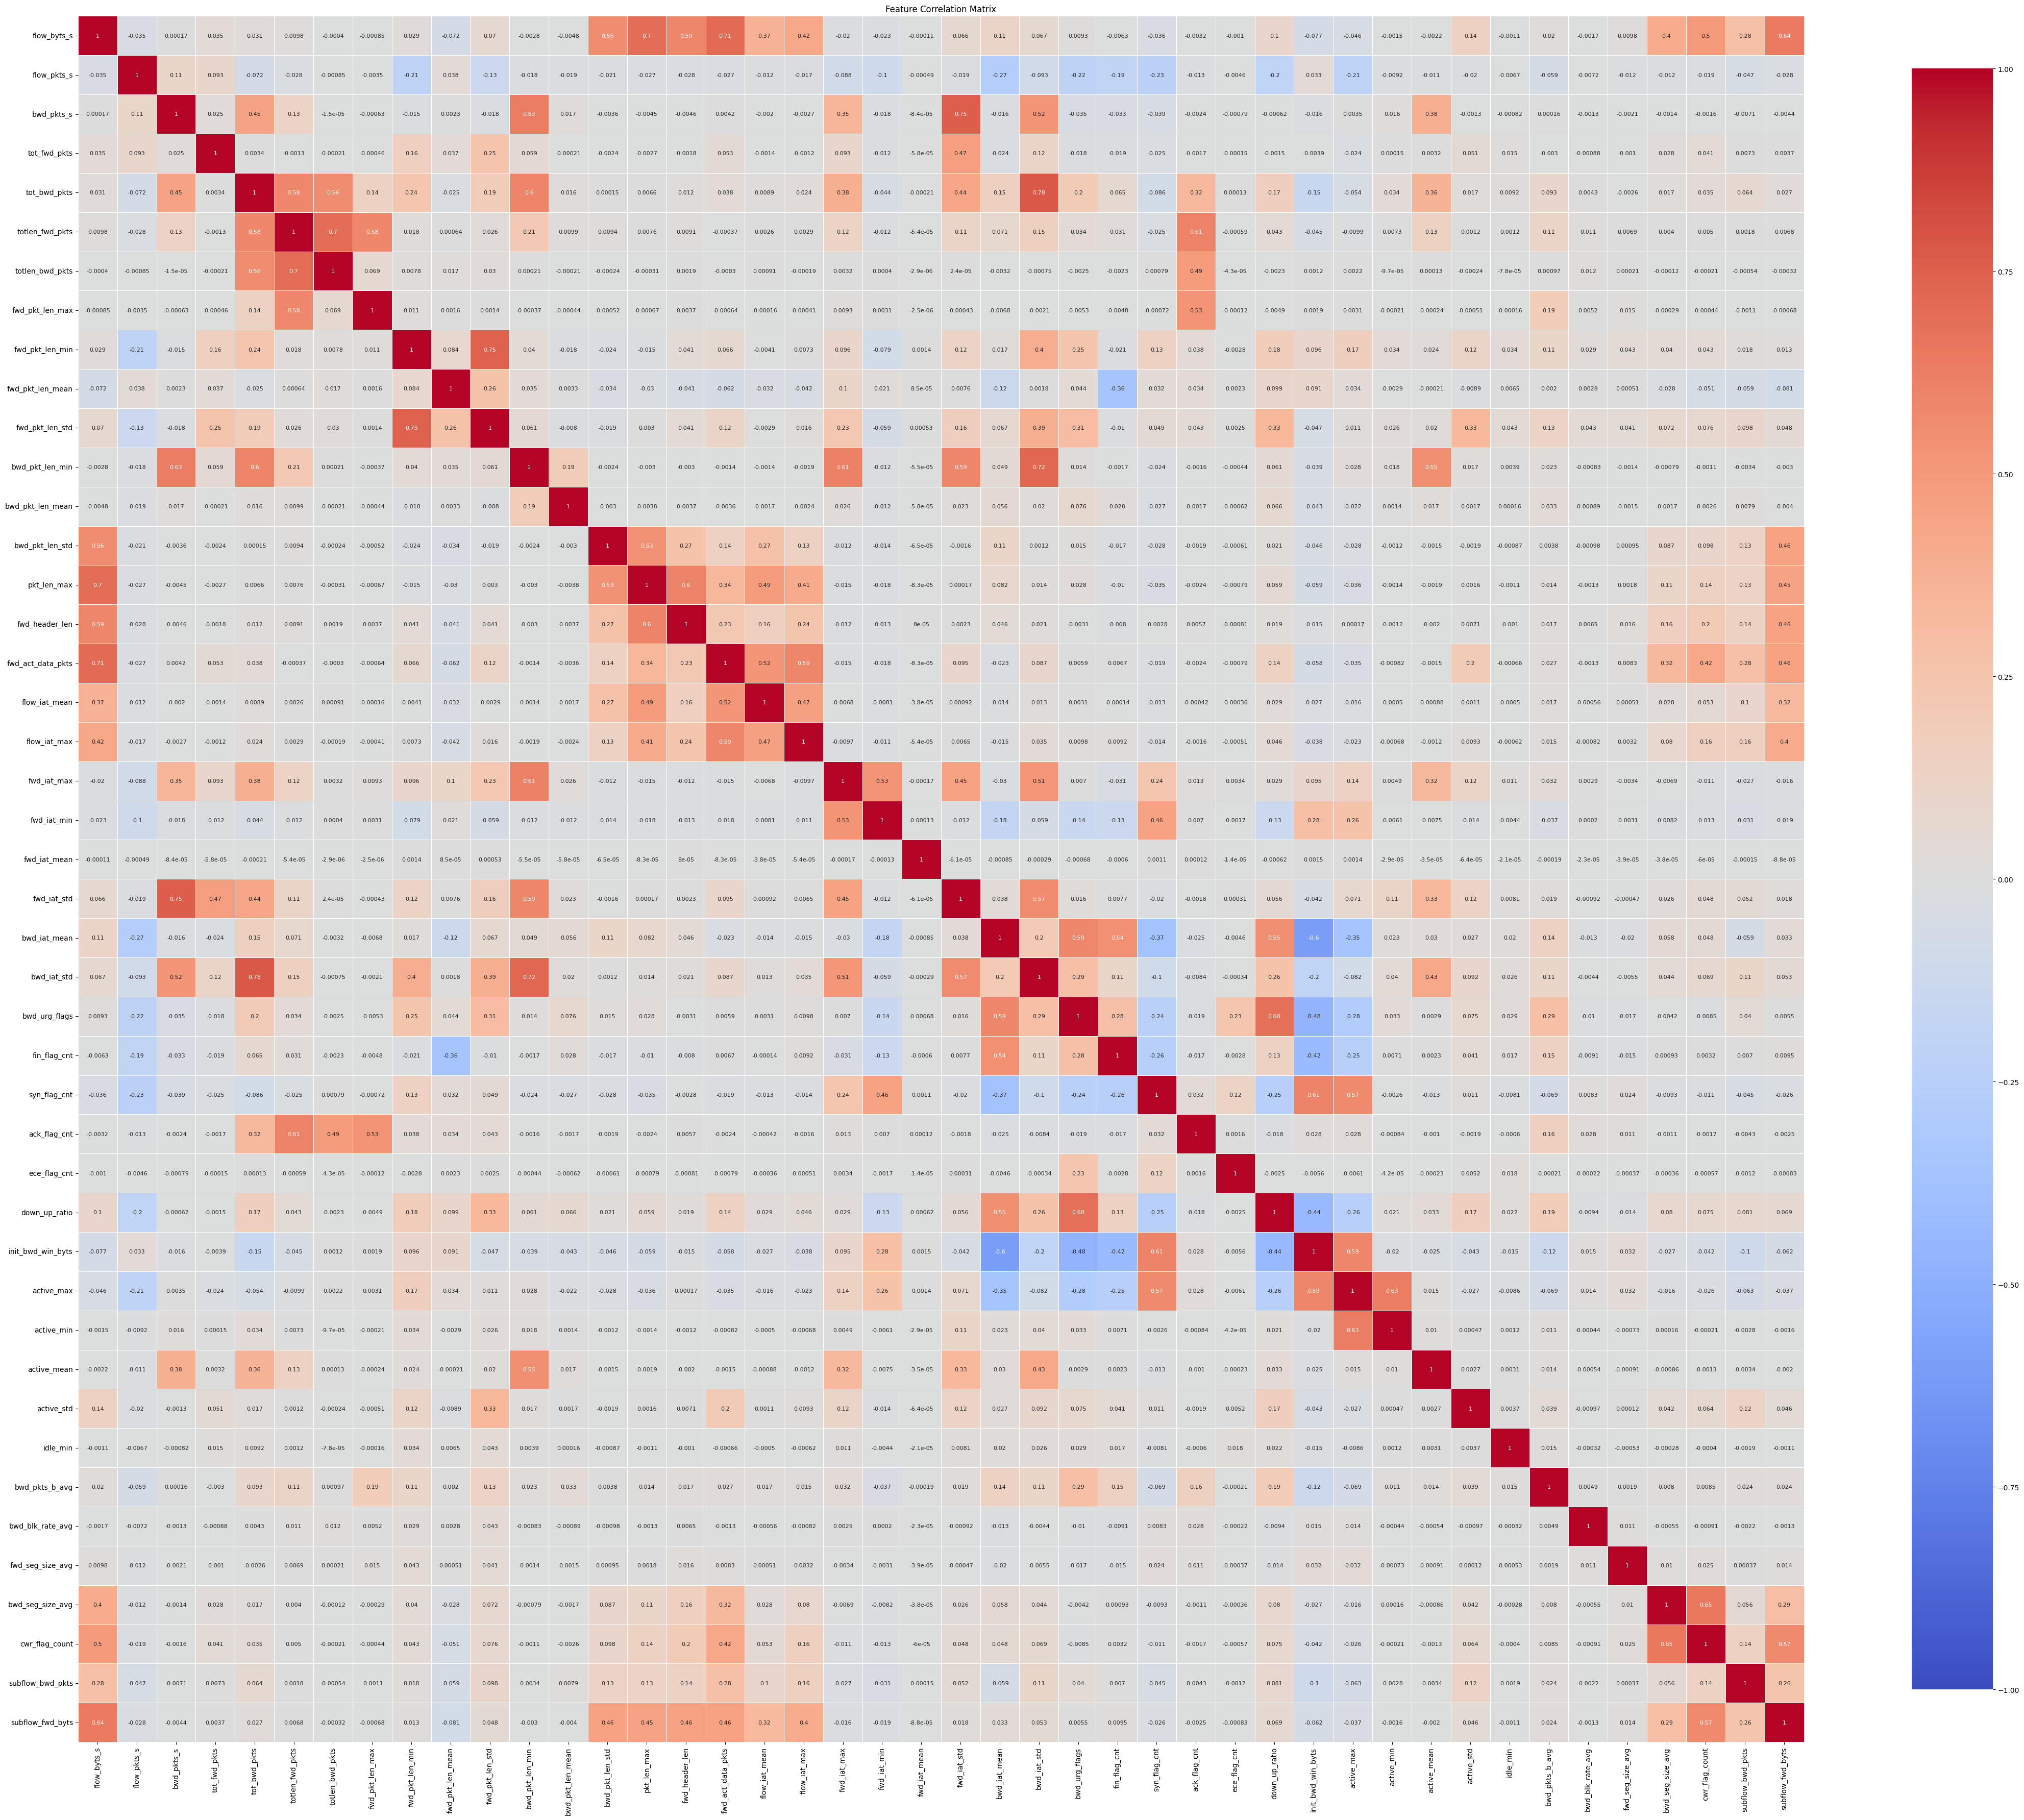

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

numeric_df = merged_df.select_dtypes(include=[np.number])

# Drop Label column
numeric_df = numeric_df.drop(columns=["Label"], errors="ignore")

# Correlation matrix
corr_matrix = numeric_df.corr()

# Create figure
plt.figure(figsize=(44, 40))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot=True,
    annot_kws={"size": 8}
)

plt.title("Feature Correlation Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

# Save BEFORE showing
plt.savefig(
    "Feature_Correlation_Matrix.png",
    dpi=500,
    bbox_inches="tight"
)

print("Saved: Feature_Correlation_Matrix.png")

plt.show()

In [19]:

# # Keep only numeric columns from merged_df
# numeric_df = merged_df.select_dtypes(include=[np.number])

# # Compute correlation matrix on numeric data
# correlation_matrix = numeric_df.corr()

# # Choose correlation column: 'Label' or 'Label_encoded'
# target_column = 'Label'  # or 'Label_encoded' if using encoded labels

# # Get correlation of all features with the label column
# label_corr = correlation_matrix[target_column]

# # Set threshold
# threshold = 0.7

# # Keep only features with abs(correlation) > threshold
# to_drop = label_corr[abs(label_corr) > threshold].index.tolist()

# # Ensure the target column is included
# if 'Label' in to_drop:
#     to_drop.remove('Label')

# # Print features to drop
# print("Features highly correlated with 'Label' (correlation ≥ 0.7):")
# print(to_drop)

# # Drop highly correlated features from the original DataFrame (keeping 'Label' column)
# reduced_df = merged_df.drop(columns=to_drop)

# # Show the shapes before and after reduction
# print("Original shape:", merged_df.shape)
# print("Reduced shape:", reduced_df.shape)

In [20]:
# import seaborn as sns
# numeric_df = reduced_df.select_dtypes(include=[np.number])

# # Drop 'Label1' if still exists
# numeric_df = numeric_df.drop(columns=['Label'], errors='ignore')

# # 3️⃣ Correlation matrix
# corr_matrix = numeric_df.corr()

# # 4️⃣ Heatmap (without annotation if features are many)
# plt.figure(figsize=(44, 40))

# sns.heatmap(
#     corr_matrix,
#     cmap='coolwarm',
#     vmin=-1, vmax=1,
#     center=0,
#     square=True,
#     linewidths=0.5,
#     cbar_kws={"shrink": 0.8},
#     annot=True,
#     annot_kws={'size': 8}  # You can increase annotation font size if you want
# )

# plt.title('Feature Correlation Matrix')
# plt.xticks(rotation=90)
# plt.yticks(rotation=0)
# plt.show()

In [21]:

# # Keep only numeric columns from merged_df
# numeric_df = merged_df.select_dtypes(include=[np.number])

# # Compute correlation matrix on numeric data
# correlation_matrix = numeric_df.corr()

# # Choose correlation column: 'Label' or 'Label_encoded'
# target_column = 'Label'  # or 'Label_encoded' if using encoded labels

# # Get correlation of all features with the label column
# label_corr = correlation_matrix[target_column]

# # Set threshold
# threshold = 0.1

# # Keep only features with abs(correlation) > threshold
# features_to_keep = label_corr[abs(label_corr) > threshold].index.tolist()

# # Ensure the target column is included
# if target_column not in features_to_keep:
#     features_to_keep.append(target_column)

# # Filter original merged_df using the selected numeric features
# merged_df = merged_df[features_to_keep]

# # Print results
# print("Kept features:", features_to_keep)
# print("Filtered shape:", merged_df.shape)


Feature matrix shape: (654417, 45)


/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


Remaining samples after outlier removal: 634791

Training Random Forest...


/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [21 29] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(



RANDOM FOREST – TRAINING SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      0.98      0.99    185349
           1       0.98      1.00      0.99    259004

    accuracy                           0.99    444353
   macro avg       0.99      0.99      0.99    444353
weighted avg       0.99      0.99      0.99    444353



<Figure size 800x600 with 0 Axes>

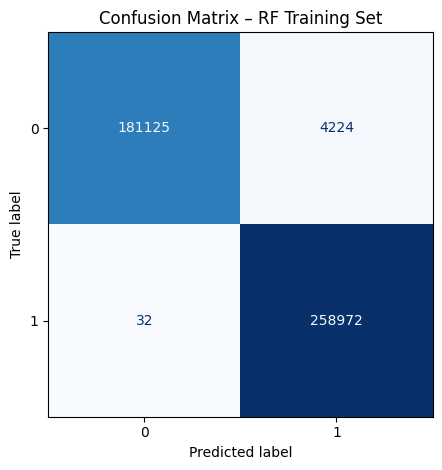

/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(



RANDOM FOREST – TEST SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     79435
           1       0.98      1.00      0.99    111003

    accuracy                           0.99    190438
   macro avg       0.99      0.99      0.99    190438
weighted avg       0.99      0.99      0.99    190438



<Figure size 800x600 with 0 Axes>

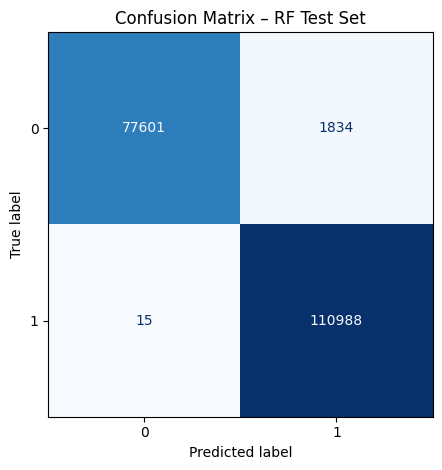


Random Forest Test Accuracy: 0.9903

Saved:
 - RF_model.pkl
 - RF_features.pkl
 - label_encoder.pkl


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest, RandomForestClassifier
# from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder


# =========================================================
# 1. BASIC CLEANING
# =========================================================

# Drop rows where Label is missing
merged_df = merged_df.dropna(subset=["Label"])

# Replace infinities
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

# Encode labels safely
label_encoder = LabelEncoder()
merged_df["Label"] = label_encoder.fit_transform(merged_df["Label"])

# Convert all feature columns to numeric safely
X = merged_df.drop(columns=["Label"]).apply(pd.to_numeric, errors="coerce")

# Keep only numeric columns
X = X.select_dtypes(include=[np.number])

y = merged_df["Label"]

# Debug check
if X.shape[1] == 0:
    raise ValueError("No numeric columns found after conversion.")

print("Feature matrix shape:", X.shape)


# =========================================================
# 2. FAST OUTLIER REMOVAL
# =========================================================

imputer_temp = SimpleImputer(strategy="mean")
X_imputed = imputer_temp.fit_transform(X)

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

mask = iso.fit_predict(X_imputed) == 1

X = X.iloc[mask]
y = y.iloc[mask]

print(f"Remaining samples after outlier removal: {len(X)}")


# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)


# =========================================================
# 4. RANDOM FOREST PIPELINE
# =========================================================

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("select", SelectKBest(score_func=f_classif, k="all")),
    ("rf", RandomForestClassifier(
        max_depth=4,
        random_state=3,
        n_jobs=-1
    ))
])

print("\nTraining Random Forest...")
rf_pipeline.fit(X_train, y_train)

# =========================================================
# 5. TRAINING SET EVALUATION
# =========================================================

y_train_pred = rf_pipeline.predict(X_train)

print("\nRANDOM FOREST – TRAINING SET PERFORMANCE")
print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – RF Training Set")
plt.tight_layout()
plt.show()


# =========================================================
# 6. TEST SET EVALUATION
# =========================================================

y_test_pred = rf_pipeline.predict(X_test)

# Predicted probabilities
y_test_proba = rf_pipeline.predict_proba(X_test)

# Probability of class 1
y_test_proba_rf = y_test_proba[:, 1]

print("\nRANDOM FOREST – TEST SET PERFORMANCE")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – RF Test Set")
plt.tight_layout()
plt.show()


# =========================================================
# 7. FINAL ACCURACY
# =========================================================

test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nRandom Forest Test Accuracy: {test_accuracy:.4f}")


# =========================================================
# 8. SAVE MODEL + SELECTED FEATURES
# =========================================================

joblib.dump(rf_pipeline, "RF_model.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

# Get selected features
selector = rf_pipeline.named_steps["select"]
selected_features = X.columns
joblib.dump(selected_features.tolist(), "RF_features.pkl")

print("\nSaved:")
print(" - RF_model.pkl")
print(" - RF_features.pkl")
print(" - label_encoder.pkl")

Feature matrix shape: (654417, 45)


/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


Remaining samples after outlier removal: 634791
Training samples: 444353
Testing samples: 190438

Training XGBoost...


/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [21 29] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(



XGBOOST – TRAINING SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    185349
           1       1.00      1.00      1.00    259004

    accuracy                           1.00    444353
   macro avg       1.00      1.00      1.00    444353
weighted avg       1.00      1.00      1.00    444353



<Figure size 800x600 with 0 Axes>

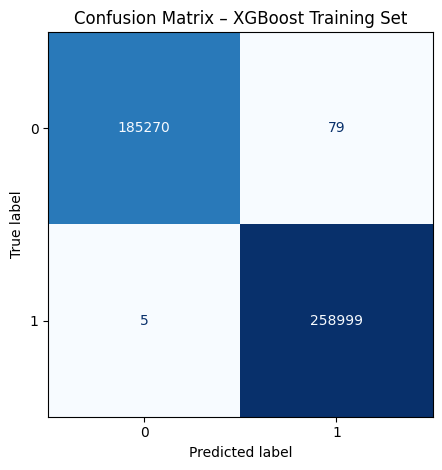

/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(



XGBOOST – TEST SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     79435
           1       1.00      1.00      1.00    111003

    accuracy                           1.00    190438
   macro avg       1.00      1.00      1.00    190438
weighted avg       1.00      1.00      1.00    190438



<Figure size 800x600 with 0 Axes>

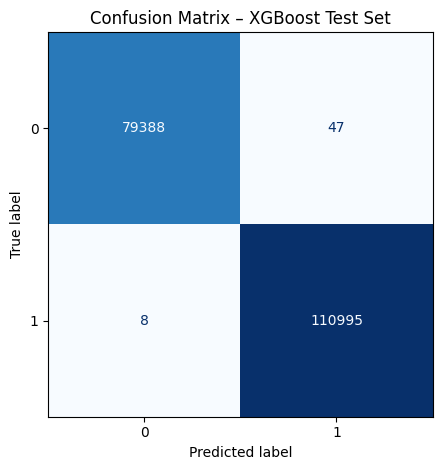


XGBoost Test Accuracy: 0.9997

Saved:
 - XGB_model.pkl
 - XGB_features.pkl
 - label_encoder.pkl


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder

from xgboost import XGBClassifier


# =========================================================
# 1. BASIC CLEANING
# =========================================================

# Drop rows where Label is missing
merged_df = merged_df.dropna(subset=["Label"])

# Replace infinities
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

# Encode labels safely
label_encoder = LabelEncoder()
merged_df["Label"] = label_encoder.fit_transform(merged_df["Label"])

# Convert all feature columns to numeric safely
X = merged_df.drop(columns=["Label"]).apply(pd.to_numeric, errors="coerce")

# Keep only numeric columns
X = X.select_dtypes(include=[np.number])

y = merged_df["Label"]

# Debug check
if X.shape[1] == 0:
    raise ValueError("No numeric columns found after conversion.")

print("Feature matrix shape:", X.shape)


# =========================================================
# 2. FAST OUTLIER REMOVAL
# =========================================================

imputer_temp = SimpleImputer(strategy="mean")
X_imputed = imputer_temp.fit_transform(X)

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

mask = iso.fit_predict(X_imputed) == 1

X = X.iloc[mask]
y = y.iloc[mask]

print(f"Remaining samples after outlier removal: {len(X)}")


# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# =========================================================
# 4. XGBOOST PIPELINE
# =========================================================

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k="all")),
    ("xgb", XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ))
])

print("\nTraining XGBoost...")
xgb_pipeline.fit(X_train, y_train)


# =========================================================
# 5. TRAINING SET EVALUATION
# =========================================================

y_train_pred = xgb_pipeline.predict(X_train)

print("\nXGBOOST – TRAINING SET PERFORMANCE")
print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – XGBoost Training Set")
plt.tight_layout()
plt.show()


# =========================================================
# 6. TEST SET EVALUATION
# =========================================================

y_test_pred = xgb_pipeline.predict(X_test)
y_test_proba = xgb_pipeline.predict_proba(X_test)

# Probability of class 1
y_test_proba_xgb = y_test_proba[:, 1]
print("\nXGBOOST – TEST SET PERFORMANCE")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – XGBoost Test Set")
plt.tight_layout()
plt.show()


# =========================================================
# 7. FINAL ACCURACY
# =========================================================

test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nXGBoost Test Accuracy: {test_accuracy:.4f}")


# =========================================================
# 8. SAVE MODEL + SELECTED FEATURES
# =========================================================

joblib.dump(xgb_pipeline, "XGB_model.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

selector = xgb_pipeline.named_steps["select"]
selected_features = X.columns

joblib.dump(selected_features.tolist(), "XGB_features.pkl")
scaler = xgb_pipeline.named_steps["scaler"]
joblib.dump(scaler, "scaler.pkl")
print("\nSaved:")
print(" - XGB_model.pkl")
print(" - XGB_features.pkl")
print(" - label_encoder.pkl")

Feature matrix shape: (654417, 45)


/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


Remaining samples after outlier removal: 634791
Training samples: 444353
Testing samples: 190438

Training KNN...


/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [21 29] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(



KNN – TRAINING SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    185349
           1       1.00      1.00      1.00    259004

    accuracy                           1.00    444353
   macro avg       1.00      1.00      1.00    444353
weighted avg       1.00      1.00      1.00    444353



<Figure size 800x600 with 0 Axes>

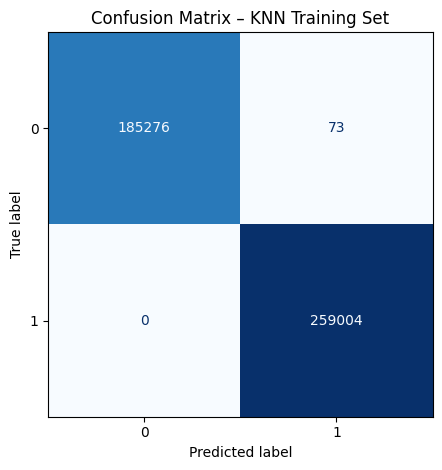

/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(



KNN – TEST SET PERFORMANCE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     79435
           1       1.00      1.00      1.00    111003

    accuracy                           1.00    190438
   macro avg       1.00      1.00      1.00    190438
weighted avg       1.00      1.00      1.00    190438



<Figure size 800x600 with 0 Axes>

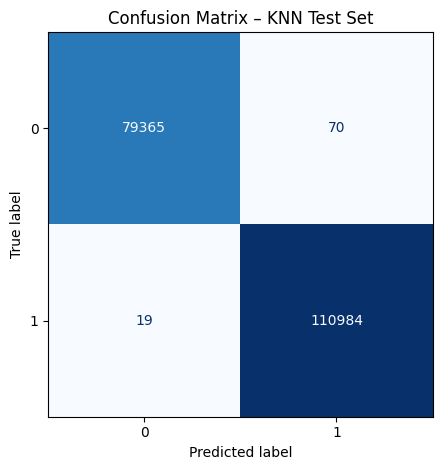

Saved Knn_Prob_Class1.csv

KNN Test Accuracy: 0.9995

Saved:
 - KNN_model.pkl
 - KNN_features.pkl
 - label_encoder.pkl


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier


# =========================================================
# 1. BASIC CLEANING
# =========================================================

# Drop rows where Label is missing
merged_df = merged_df.dropna(subset=["Label"])

# Replace infinities
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

# Encode labels
label_encoder = LabelEncoder()
merged_df["Label"] = label_encoder.fit_transform(merged_df["Label"])

# Convert features to numeric
X = merged_df.drop(columns=["Label"]).apply(pd.to_numeric, errors="coerce")

# Keep numeric columns only
X = X.select_dtypes(include=[np.number])

y = merged_df["Label"]

if X.shape[1] == 0:
    raise ValueError("No numeric columns found.")

print("Feature matrix shape:", X.shape)


# =========================================================
# 2. FAST OUTLIER REMOVAL
# =========================================================

imputer_temp = SimpleImputer(strategy="mean")
X_imputed = imputer_temp.fit_transform(X)

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

mask = iso.fit_predict(X_imputed) == 1

X = X.iloc[mask]
y = y.iloc[mask]

print(f"Remaining samples after outlier removal: {len(X)}")


# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# =========================================================
# 4. KNN PIPELINE
# =========================================================

knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),     # important for KNN
    ("select", SelectKBest(score_func=f_classif, k="all")),
    ("knn", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ))
])

print("\nTraining KNN...")
knn_pipeline.fit(X_train, y_train)


# =========================================================
# 5. TRAINING SET EVALUATION
# =========================================================

y_train_pred = knn_pipeline.predict(X_train)

print("\nKNN – TRAINING SET PERFORMANCE")
print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – KNN Training Set")
plt.tight_layout()
plt.show()


# =========================================================
# 6. TEST SET EVALUATION
# =========================================================

y_test_pred = knn_pipeline.predict(X_test)

# Class 1 probability
y_test_proba_knn = (
    knn_pipeline.predict_proba(X_test)[:,1]
)
print("\nKNN – TEST SET PERFORMANCE")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)

plt.figure(figsize=(8,6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=label_encoder.classes_.astype(str),
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix – KNN Test Set")
plt.tight_layout()
plt.show()

knn_prob_df = pd.DataFrame({
    "Actual_Label": y_test.values,
    "Predicted_Label": y_test_pred,
    "SVM_Prob_Class1": y_test_proba_knn
})

knn_prob_df.to_csv(
    "Knn_Prob_Class1.csv",
    index=False
)

print("Saved Knn_Prob_Class1.csv")


# =========================================================
# 7. FINAL ACCURACY
# =========================================================

test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"\nKNN Test Accuracy: {test_accuracy:.4f}")


# =========================================================
# 8. SAVE MODEL + FEATURES
# =========================================================

joblib.dump(knn_pipeline, "KNN_model.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

selector = knn_pipeline.named_steps["select"]
selected_features = X.columns

joblib.dump(selected_features.tolist(), "KNN_features.pkl")

print("\nSaved:")
print(" - KNN_model.pkl")
print(" - KNN_features.pkl")
print(" - label_encoder.pkl")

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV


# =========================================================
# 1. BASIC CLEANING
# =========================================================
print(merged_df.shape)
# Drop rows where Label is missing
merged_df = merged_df.dropna(subset=["Label"])

# Replace infinities
merged_df = merged_df.replace([np.inf, -np.inf], np.nan)

# Encode labels safely
label_encoder = LabelEncoder()
merged_df["Label"] = label_encoder.fit_transform(merged_df["Label"])

# Convert all feature columns to numeric safely
X = merged_df.drop(columns=["Label"]).apply(pd.to_numeric, errors="coerce")

# Keep only numeric columns
X = X.select_dtypes(include=[np.number])

y = merged_df["Label"]

# Debug check
if X.shape[1] == 0:
    raise ValueError("No numeric columns found after conversion.")

print("Feature matrix shape:", X.shape)


# =========================================================
# 2. FAST OUTLIER REMOVAL
# =========================================================

imputer_temp = SimpleImputer(strategy="mean")
X_imputed = imputer_temp.fit_transform(X)

iso = IsolationForest(
    contamination=0.03,
    n_estimators=30,
    max_samples=0.7,
    random_state=34,
    n_jobs=-1
)

mask = iso.fit_predict(X_imputed) == 1

X = X.iloc[mask]
y = y.iloc[mask]

print(f"Remaining samples after outlier removal: {len(X)}")


# =========================================================
# 3. TRAIN–TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)


# =========================================================
# 4. SVM PIPELINE
# =========================================================

svm_pipeline = Pipeline([

    # SAME imputation
    (
        "imputer",
        SimpleImputer(
            strategy="mean"
        )
    ),


    # Required for SVM
    (
        "scaler",
        StandardScaler()
    ),


    # SAME feature selection
    (
        "select",
        SelectKBest(
            score_func=f_classif,
            k="all"
        )
    ),


    # SVM with probability
    (
        "svm",
        CalibratedClassifierCV(
            LinearSVC(
                C=1.0,
                max_iter=5000,
                random_state=42
            ),
            cv=3
        )
    )

])


print("\nTraining SVM...")

svm_pipeline.fit(
    X_train,
    y_train
)



# =========================================================
# 5. TRAINING PERFORMANCE
# =========================================================

y_train_pred = svm_pipeline.predict(
    X_train
)


print("\nSVM TRAINING PERFORMANCE")

print(
    classification_report(
        y_train,
        y_train_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)



# =========================================================
# 6. TEST PERFORMANCE + PROBABILITY
# =========================================================

y_test_pred = svm_pipeline.predict(
    X_test
)


# Class 1 probability
y_test_proba_svm = (
    svm_pipeline
    .predict_proba(X_test)[:,1]
)


print("\nFirst 10 SVM Class-1 probabilities:")
print(y_test_proba_svm[:10])


print("\nSVM TEST PERFORMANCE")

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=label_encoder.classes_.astype(str)
    )
)



# =========================================================
# 7. ACCURACY
# =========================================================

accuracy = accuracy_score(
    y_test,
    y_test_pred
)


print(
    "\nSVM Test Accuracy:",
    round(accuracy,4)
)



# =========================================================
# 8. SAVE PROBABILITY CSV
# =========================================================
svm_prob_df = pd.DataFrame({
    "Actual_Label": y_test.values,
    "Predicted_Label": y_test_pred,
    "SVM_Prob_Class1": y_test_proba_svm
})

svm_prob_df.to_csv(
    "SVM_Prob_Class1.csv",
    index=False
)

print("Saved SVM_Prob_Class1.csv")


# =========================================================
# 9. SAVE MODEL
# =========================================================

joblib.dump(
    svm_pipeline,
    "SVM_model.pkl"
)


joblib.dump(
    label_encoder,
    "label_encoder.pkl"
)


joblib.dump(
    X.columns.tolist(),
    "SVM_features.pkl"
)


print("\nSaved:")
print("SVM_model.pkl")
print("SVM_features.pkl")
print("label_encoder.pkl")

(654417, 46)
Feature matrix shape: (654417, 45)


/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


Remaining samples after outlier removal: 634791

Training SVM...


/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [21 29] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/home/znb/.local/lib/python3.10/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw
/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(



SVM TRAINING PERFORMANCE
              precision    recall  f1-score   support

           0       0.98      0.98      0.98    185349
           1       0.99      0.99      0.99    259004

    accuracy                           0.99    444353
   macro avg       0.99      0.99      0.99    444353
weighted avg       0.99      0.99      0.99    444353



/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/home/znb/.local/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: ['flow_duration']. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(



First 10 SVM Class-1 probabilities:
[8.65042776e-24 2.84421420e-01 2.07714432e-47 9.83027562e-01
 9.84015961e-01 2.14927406e-05 9.86451990e-01 2.68633184e-21
 9.82744065e-01 9.82344365e-01]

SVM TEST PERFORMANCE
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     79435
           1       0.99      0.99      0.99    111003

    accuracy                           0.99    190438
   macro avg       0.99      0.98      0.99    190438
weighted avg       0.99      0.99      0.99    190438


SVM Test Accuracy: 0.9856
Saved SVM_Prob_Class1.csv

Saved:
SVM_model.pkl
SVM_features.pkl
label_encoder.pkl


In [26]:
# prob_df = pd.DataFrame()

# prob_df["RF_ProbClass1"] = y_test_proba_rf
# prob_df["KNN_ProbClass1"] = y_test_proba_knn
# prob_df["XGB_ProbClass1"] = y_test_proba_xgb
# prob_df["SVM_ProbClass1"] = y_test_proba_svm

# # Save
# prob_df.to_csv(
#     "All_Model_Probability.csv",
#     index=False
# )
# print("Saved All_Model_Probabilities.csv")

In [27]:
overall = (
    y_test_proba_rf +
    y_test_proba_knn +
    y_test_proba_xgb +
    y_test_proba_svm
) / 4

threshold = 0.70

prediction = np.where(overall > threshold, 1, 0)


In [28]:
# from sklearn.ensemble import VotingClassifier
# from sklearn.pipeline import Pipeline
# from sklearn.impute import SimpleImputer
# from sklearn.feature_selection import SelectKBest, f_classif
# from sklearn.preprocessing import StandardScaler
# from sklearn.metrics import classification_report, accuracy_score
# import joblib

# # --- Hybrid Pipeline ---
# hybrid_pipeline = Pipeline([
#     ("imputer", SimpleImputer(strategy="mean")),
#     ("select", SelectKBest(score_func=f_classif)),
#     ("scaler", StandardScaler()),  # needed for KNN & MLP
    
#     ("ensemble", VotingClassifier(
#         estimators=[
#             ("knn", knn_pipeline),
#             ("xgboost", xgb_pipeline),
#             ("rf", rf_pipeline)
#         ],
#         voting="hard",
#         weights=[3, 7, 5],   # one weight per model
#         n_jobs=-1
#     ))
# ])

# print("\nRunning HYBRID Ensemble...")
# hybrid_pipeline.fit(X_train, y_train)

# # =========================================================
# # TEST EVALUATION
# # =========================================================

# y_test_pred_hybrid = hybrid_pipeline.predict(X_test)

# print("\nHYBRID MODEL – TEST SET PERFORMANCE")

# print(classification_report(
#     y_test,
#     y_test_pred_hybrid,
#     target_names=label_encoder.classes_.astype(str)
# ))

# print("Hybrid Accuracy:",
#       accuracy_score(y_test, y_test_pred_hybrid))

# # =========================================================
# # SAVE HYBRID MODEL
# # =========================================================

# joblib.dump(hybrid_pipeline, "AD_Hybrid_model.pkl")

# print("Saved Hybrid_model.pkl")